# V4.0 — Group 18–20: Full-Window Sweep + Independent 1025-RF CeNN + Tied 128-Radius Iterations

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vtavakkoli/TinyCeNN-LM/blob/main/notebooks/Laya_V40_Group18_20_FullWindow_CeNN1025_128_Sweep_Colab.ipynb)

### Test the weakest V3.9 group, not all 28 blocks

The uploaded V3.9 report recorded **cosine 0.7753** for group (18,19,20), while the fully compressed model fell to **39.5% teacher agreement / 35% gold accuracy**. We therefore keep every other original encoder layer unchanged and experiment only with **original full-attention layer 18 + original sliding layers 19 and 20**.

**Your proposed design, expressed precisely:**
1. Original full-attention block 18, including pretrained QKV, RoPE, native SDPA and FFN, uses a **full-attention window sweep** of **128, 256, 384, 512, 768, 1024 total key positions** (not radii). Nonlocal keys are masked for smaller windows. Its pretrained weights stay frozen.
2. A **separate long-range CeNN weight** uses depthwise kernel 9, dilation 128, giving receptive field **1025** (±512 positions) and its own channel mixing, applied once. This is an **RF of 1025 tokens, not 1025 recurrent iterations**.
3. A **local CeNN weight** uses depthwise kernel 9, dilation 32, giving **radius 128** (width 257). This **identical weight** is reused for each local step, normally twice: \`x → local(W) → local(W)\`, with separate scalar gains for steps. Also compare 1 and 3 iterations to determine whether recurrence helps. An optional untied two-step control is included for testing whether weight sharing is the bottleneck.
4. The resulting **Global + CeNN(1025) + Repeated CeNN(±128)** replaces original blocks 18–20. Other 25 pretrained blocks stay original. Compare *with/without long-range branch*, train local steps against teacher 19/20 outputs, and measure whole-model decisions + CUDA latency.

**Important context limitation:** Original V3.9 capped \`MAX_LEN=512\` and \`source_cfg.max_len\` may further cap actual sequences. If every sample has at most 512 tokens, full windows 512/768/1024 can be mathematically identical; this notebook prints their observed equivalence and **does not claim a separate W1024 quality result** unless genuinely longer sequences were evaluated. Optionally enable \`ALLOW_EXTENDED_CONTEXT=True\` and \`MAX_LEN=1024\`; the notebook first checks encoder positional capacity and that longer actual examples exist. Exceeding the original task's trained length is an extrapolation experiment, not the same benchmark.

### Reproducible protocol

- Case-disjoint **TRAIN, PROBE, AUDIT** from dataset TRAIN split; official TEST untouched.
- First compare all six *pretrained full-window* settings **while keeping slides 19–20 original** on PROBE. Identify equivalent windows by observed context length. Keep up to two distinctive windows, always including the unchanged/full setting as a reference.
- Capture original teacher **input to block 18**, outputs after blocks 18, 19 and 20, and the true ModernBERT call kwargs (including both masks). Train CeNN variants on input generated by each candidate full window and original teacher y19/y20 targets. CPU FP16 teacher caches; gradients only through small CeNN modules.
- Initial architecture search over: full window × local recurrence (1/2/3) × separate 1025-RF branch (on/off); rank by **PROBE downstream teacher agreement, gold accuracy and segment delta fidelity**, not raw hidden-state cosine alone.
- Refine the strongest PROBE candidates with additional steps; optional separate-weight (untied) recurrence control. Save a checkpoint after each trial and allow resume.
- Evaluate the selected model on untouched AUDIT **once**, with causal CeNN branch ablations and matched, interleaved native-versus-student CUDA timings. If agreement/accuracy/speed gates fail, label checkpoint *experimental only*. Native teacher remains available unchanged.

**Defaults**: two distinct full windows, 3 local recurrence counts, long-range branch on/off; two-stage training on a T4. This may take substantial Colab GPU time. The pretrained model is loaded only once and never overwritten.

**Acceptance goals (not achieved yet):** teacher agreement ≥95%, gold drop ≤1 percentage point, actual full-model paired speedup >1× and segment cosine ≥0.99. No results are claimed until Colab runs.

### Native replay bug fix (October 2026)
The original V4.0 cached the global block input `before` and the original `y18` in FP16, even though ModernBERT's residual hidden states can be FP32. Thus checking a re-evaluated window-1024 output against a separately quantized teacher output gave a spurious absolute error up to 8. The notebook now preserves those two tensors and native kwargs at source precision, performs **exact no-op mask equality**, directly compares native-versus-window replay on **identical cached inputs**, and reports a **separate** full-precision original-forward check. A numerically inconsistent input is not allowed into CeNN training. Because older in-memory caches are already lossy, re-run cell 6 from the beginning after refreshing this notebook.


In [1]:
#@title 1. Install pinned V4.0 dependencies and GPU check
%pip -q install "transformers==4.57.6" "datasets>=2.20" "huggingface_hub>=0.25,<1" "safetensors>=0.4"
%pip -q install -U "git+https://github.com/vtavakkoli/TinyCeNN-LM.git@main"
import torch
assert torch.cuda.is_available(), "Select Runtime > Change runtime type > GPU (T4 or better)."
print("CUDA",torch.version.cuda,"GPU",torch.cuda.get_device_name(0),"Torch",torch.__version__)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 55.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
CUDA 13.0 GPU Tesla T4 Torch 2.11.0+cu130


In [2]:
#@title 2. Frozen pretrained Laya and V4.0 experiment configuration
from pathlib import Path
from contextlib import contextmanager
import copy, json, math, random, time, hashlib, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer
from tinycenn_lm.standalone_decision import (
    QTYPES, build_checkpoint_model, build_sequence,
    collate_items, normalize_question, full_attention_indices,
)
from tinycenn_lm.decision_training import require_finite

SOURCE_MODEL="convaiinnovations/laya-typed-decisions"
SEED=2040
TARGET=(18,19,20)
MAX_LEN=512 #@param {type:"integer"}
ALLOW_EXTENDED_CONTEXT=False #@param {type:"boolean"}
FULL_WINDOWS=(128,256,384,512,768,1024)
LOCAL_RADIUS=128
LONG_RF=1025
CENN_RANK=96 #@param {type:"integer"}
ITERATION_CANDIDATES=(1,2,3)
LONG_BRANCH_CANDIDATES=(False,True)
TRAIN_CASES=500 #@param {type:"integer"}
DEV_CASES=240 #@param {type:"integer"}
BATCH=2 #@param {type:"integer"}
TRAIN_CACHE_BATCHES=96 #@param {type:"integer"}
PROBE_CACHE_BATCHES=20 #@param {type:"integer"}
AUDIT_CACHE_BATCHES=12 #@param {type:"integer"}
SHORT_TRAIN_STEPS=100 #@param {type:"integer"}
REFINE_EXTRA_STEPS=300 #@param {type:"integer"}
TOP_DISTINCT_WINDOWS=2 #@param {type:"integer"}
REFINE_TOP_CANDIDATES=2 #@param {type:"integer"}
RUN_UNTIED_CONTROL=True #@param {type:"boolean"}
WINDOW_SCREEN_DECISIONS=100 #@param {type:"integer"}
CANDIDATE_PROBE_DECISIONS=100 #@param {type:"integer"}
AUDIT_DECISIONS=200 #@param {type:"integer"}
CHECK_EVERY=50 #@param {type:"integer"}
LEARNING_RATE=0.0008 #@param {type:"number"}
BENCH_REPEATS=8 #@param {type:"integer"}
RESUME=True #@param {type:"boolean"}
SAVE_TO_GOOGLE_DRIVE=False #@param {type:"boolean"}
OUTPUT_DIR=Path("/content/Laya_V40_Group18_20_CeNN")
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
if SAVE_TO_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR=Path("/content/drive/MyDrive/TinyCeNN-LM/V40_Group18_20")
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
assert TARGET==(18,19,20) and 1<=BATCH<=4
assert 1<=TOP_DISTINCT_WINDOWS<=len(FULL_WINDOWS)
assert 1<=REFINE_TOP_CANDIDATES<=12
assert MAX_LEN<=1024 and TRAIN_CACHE_BATCHES>=1 and PROBE_CACHE_BATCHES>=1
assert TRAIN_CASES+DEV_CASES<=1200
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device=torch.device("cuda")
amp_dtype=(torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False)
           else torch.float16)
source_dir=Path(snapshot_download(
    SOURCE_MODEL,allow_patterns=[
        "rl_agent_config.json","model.safetensors","encoder/*","tokenizer/*"
    ]
))
teacher,source_cfg=build_checkpoint_model(source_dir)
teacher.to(device).eval().requires_grad_(False)
teacher.encoder.config.reference_compile=False
tokenizer=AutoTokenizer.from_pretrained(str(source_dir/"tokenizer"))
FULL_LAYERS=full_attention_indices(teacher)
assert list(FULL_LAYERS)==[0,3,6,9,12,15,18,21,24,27]
assert len(teacher.encoder.layers)==28
assert TARGET[0] in FULL_LAYERS and TARGET[1] not in FULL_LAYERS and TARGET[2] not in FULL_LAYERS
assert int(teacher.encoder.config.local_attention)//2==64
if ALLOW_EXTENDED_CONTEXT:
    limit=int(getattr(teacher.encoder.config,"max_position_embeddings",0))
    if MAX_LEN>limit:
        raise RuntimeError(f"Extended length {MAX_LEN} exceeds encoder position limit {limit}.")
elif MAX_LEN>int(source_cfg.get("max_len",MAX_LEN)):
    raise RuntimeError("Use MAX_LEN at or below source trained length, or explicitly opt into extended context.")
print("Pretrained original layers:",len(teacher.encoder.layers),"target",TARGET)
print("Native slide radius",int(teacher.encoder.config.local_attention)//2)
print("Full window candidates",FULL_WINDOWS,"local CeNN radius",LOCAL_RADIUS,
      "long-range RF",LONG_RF)
print("CUDA:",torch.cuda.get_device_name(0),"AMP:",amp_dtype)
print("Task pretrained max_len",source_cfg.get("max_len"),"requested",MAX_LEN)


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

rl_agent_config.json:   0%|          | 0.00/847 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/337 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/843M [00:00<?, ?B/s]

Pretrained original layers: 28 target (18, 19, 20)
Native slide radius 64
Full window candidates (128, 256, 384, 512, 768, 1024) local CeNN radius 128 long-range RF 1025
CUDA: Tesla T4 AMP: torch.float16
Task pretrained max_len 1024 requested 512


In [3]:
#@title 3. Leak-free train/dev data and teacher I/O helpers
def _jsonish(x):
    if isinstance(x, str):
        try:
            return json.loads(x)
        except Exception:
            return x
    return x

def _canon_label(x):
    s = str(x).strip().lower()
    try:
        v = float(s)
        if math.isfinite(v) and v.is_integer():
            return str(int(v))
    except Exception:
        pass
    return s

def _gold_metadata(q, gold_answer):
    if not isinstance(gold_answer, dict):
        raise ValueError("missing gold answer")
    probs_raw = _jsonish(gold_answer.get("probabilities", {}))
    if not isinstance(probs_raw, dict) or len(probs_raw) < 2:
        raise ValueError("gold probabilities missing or malformed")

    gold_keys = [str(k) for k in probs_raw.keys()]
    if q["t"] == "choice":
        labels = [str(k) for k in q["crit"].keys()]
    elif q["t"] == "noul":
        labels = ["false", "true"]
    else:
        labels = list(gold_keys)
        if all(_canon_label(k).lstrip("-").isdigit() for k in labels):
            labels = sorted(labels, key=lambda k: int(_canon_label(k)))

    lookup = {_canon_label(k): float(v) for k, v in probs_raw.items()}
    if len(labels) != len(gold_keys) or any(_canon_label(k) not in lookup for k in labels):
        raise ValueError("Gold labels do not match encoded option order")

    gold_probs = np.asarray([lookup[_canon_label(k)] for k in labels], dtype=np.float64)
    gold_probs = np.clip(gold_probs, 0.0, None)
    if not np.isfinite(gold_probs).all() or gold_probs.sum() <= 0:
        raise ValueError("invalid gold probability vector")
    gold_probs /= gold_probs.sum()

    gold_label = _canon_label(gold_answer.get("label", labels[int(gold_probs.argmax())]))
    canon_labels = [_canon_label(k) for k in labels]
    if gold_label not in canon_labels:
        raise ValueError(f"gold label {gold_label!r} not in {labels!r}")
    return labels, gold_probs.tolist(), canon_labels.index(gold_label)

def make_items_from_rows(rows, seed, shuffle_items):
    out = []
    head_max_len = int(source_cfg.get("head_max_len", 192))
    for row in rows:
        state = _jsonish(row["state"])
        questions = _jsonish(row["questions"])
        gold = _jsonish(row["gold"])
        case_id = str(row.get("id", ""))
        workflow = str(row.get("workflow", "unknown"))
        state_text = state if isinstance(state, str) else json.dumps(state, ensure_ascii=False)
        state_ids = tokenizer(
            state_text.replace(tokenizer.mask_token, " "),
            add_special_tokens=False,
        )["input_ids"]

        for qid, qdef in questions.items():
            q = normalize_question(qdef)
            ids, markers = build_sequence(
                tokenizer,
                state,
                q,
                max_len=(MAX_LEN if ALLOW_EXTENDED_CONTEXT else
                         min(MAX_LEN, int(source_cfg.get("max_len", MAX_LEN)))),
                head_max_len=head_max_len,
                truncate_left=isinstance(state, list),
                state_ids=state_ids,
            )
            if len(markers) < 2:
                continue
            labels, gold_probs, gold_index = _gold_metadata(q, gold[qid])
            if len(labels) != len(markers):
                raise ValueError(
                    f"{case_id}/{qid}: {len(markers)} markers vs {len(labels)} gold labels"
                )
            out.append({
                "ids": ids,
                "markers": markers,
                "qtype": QTYPES[q["t"]],
                "qtype_name": q["t"],
                "qid": str(qid),
                "case_id": case_id,
                "workflow": workflow,
                "labels": labels,
                "gold_probs": gold_probs,
                "gold_index": int(gold_index),
            })
    if shuffle_items:
        random.Random(seed).shuffle(out)
    return out

rows = list(load_dataset("LocalLLaMA/typed-decisions", "all", split="train"))
rng = random.Random(SEED)
rng.shuffle(rows)
assert TRAIN_CASES + DEV_CASES <= len(rows)
train_rows = rows[:TRAIN_CASES]
dev_rows = rows[TRAIN_CASES:TRAIN_CASES + DEV_CASES]
train_items = make_items_from_rows(train_rows, SEED, True)
# Split at the CASE level before creating multiple question items per case.
probe_rows = dev_rows[:len(dev_rows) // 2]
audit_rows = dev_rows[len(dev_rows) // 2:]
probe_items = make_items_from_rows(probe_rows, SEED + 1, True)
audit_items = make_items_from_rows(audit_rows, SEED + 2, True)
dev_items = probe_items # backward-compatible alias for training helper use
assert train_items and probe_items and audit_items
assert {str(r["id"]) for r in probe_rows}.isdisjoint({str(r["id"]) for r in audit_rows})

def direct_batch(selected):
    b = collate_items(selected, int(tokenizer.pad_token_id))
    return {k: v.to(device) for k, v in b.items()}

def batch(items, offset, n=BATCH):
    selected = [items[(offset + i) % len(items)] for i in range(n)]
    return direct_batch(selected)

def _snapshot_attention_argument(value):
    """Retain the exact forward inputs for ModernBERT SDPA replay/timing."""
    if torch.is_tensor(value):
        return value.detach()
    if isinstance(value, tuple):
        return tuple(_snapshot_attention_argument(v) for v in value)
    if isinstance(value, list):
        return [_snapshot_attention_argument(v) for v in value]
    if isinstance(value, dict):
        return {k: _snapshot_attention_argument(v) for k, v in value.items()}
    return value

def _attention_output_tensor(result):
    """ModernBERT variants return either tensor or (tensor, optional weights)."""
    return result[0] if isinstance(result, (tuple, list)) else result

def attn_io(model, layer_idx, b):
    layer = model.encoder.layers[layer_idx]
    got = {}
    def pre(mod, args, kwargs):
        # The encoder passes more than x/position_embeddings/attention_mask:
        # position_ids, sliding_window_mask and optional flags are required by
        # transformers 4.57.6 SDPA. Never infer these for benchmarking.
        got["call_args"] = _snapshot_attention_argument(tuple(args))
        got["call_kwargs"] = _snapshot_attention_argument(dict(kwargs))
        got["x"] = args[0].detach()
        got["pos"] = _snapshot_attention_argument(kwargs.get("position_embeddings"))
        got["mask"] = _snapshot_attention_argument(kwargs.get("attention_mask"))
    def post(mod, args, kwargs, out):
        got["y"] = _attention_output_tensor(out).detach()
    h1 = layer.attn.register_forward_pre_hook(pre, with_kwargs=True)
    h2 = layer.attn.register_forward_hook(post, with_kwargs=True)
    try:
        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=amp_dtype):
            model(**b)
    finally:
        h1.remove()
        h2.remove()
    return got

def cache_teacher_io(layer_idx, items, batches, offset=0):
    cache = []
    for i in range(batches):
        b = batch(items, offset + i * BATCH, BATCH)
        got = attn_io(teacher, layer_idx, b)
        cache.append({
            "x": got["x"],
            "pos": got["pos"],
            "mask": got["mask"],
            "call_args": got["call_args"],
            "call_kwargs": got["call_kwargs"],
            "y": got["y"],
            "valid": b["attention_mask"].bool(),
        })
    return cache

def local_metrics_from_cache(repl, cache):
    repl.eval()
    diff_sum = power_sum = cos_sum = 0.0
    tokens = 0
    with torch.no_grad():
        for entry in cache:
            with torch.autocast(device_type="cuda", dtype=amp_dtype):
                pred, _ = repl(
                    entry["x"],
                    position_ids=entry["call_kwargs"].get("position_ids"),
                    attention_mask=entry["mask"],
                )
            require_finite(pred, "V4.0 teacher helper")
            valid = entry["valid"]
            m = valid[:, :, None].float()
            d = pred.shape[-1]
            diff_sum += float((((pred.float() - entry["y"].float()) ** 2) * m).sum())
            power_sum += float(((entry["y"].float() ** 2) * m).sum())
            count = int(valid.sum())
            cos_sum += float(
                F.cosine_similarity(
                    pred.float()[valid],
                    entry["y"].float()[valid],
                    dim=-1,
                ).sum()
            )
            tokens += count
    nmse = diff_sum / max(power_sum, 1e-8)
    cosine = cos_sum / max(tokens, 1)
    score = nmse + 1.10 * (1.0 - cosine)
    return {"nmse": nmse, "cosine": cosine, "score": score, "tokens": tokens}

print("train/probe/audit decisions:", len(train_items), len(probe_items), len(audit_items))
print("unique train/probe/audit cases:", len(train_rows), len(probe_rows), len(audit_rows))
assert len(probe_items) >= PROBE_CACHE_BATCHES * BATCH, "Increase DEV_CASES or reduce PROBE_CACHE_BATCHES"
assert len(audit_items) >= AUDIT_CACHE_BATCHES * BATCH, "Increase DEV_CASES or reduce AUDIT_CACHE_BATCHES"
print("official test remains untouched")


README.md: 0.00B [00:00, ?B/s]

all/train-00000-of-00001.parquet:   0%|          | 0.00/599k [00:00<?, ?B/s]

all/test-00000-of-00001.parquet:   0%|          | 0.00/222k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400 [00:00<?, ? examples/s]

train/probe/audit decisions: 2500 600 600
unique train/probe/audit cases: 500 120 120
official test remains untouched


In [4]:
#@title 4. Exact ModernBERT full-window modifier: preserve original RoPE, FFN and native SDPA
ORIGINAL_LAYERS=tuple(teacher.encoder.layers)
ORIGINAL_FULL=ORIGINAL_LAYERS[18]
@torch.no_grad()
def observed_window_equivalence(window,observed_max):
    """Keys in a centered total-width W mask have no excluded positions if W>=2*T-1,
    but at T<=W some queries near edges can still have remote keys. We therefore
    never infer equivalence from W>=T alone: use the actual mask comparison.
    """
    T=int(observed_max)
    if T==0:return False
    return torch.equal(make_band(T,window,torch.device("cpu")),
                       torch.ones((T,T),dtype=torch.bool))

def make_band(T,width,device):
    width=int(width)
    left=(width-1)//2
    right=width-1-left
    pos=torch.arange(T,device=device)
    delta=pos[None,:]-pos[:,None]
    return (delta>=-left)&(delta<=right)

class GlobalWindow18(nn.Module):
    """Wrap the FULL original block, modifying only its additive full mask.

    Original sliding_window_mask remains unchanged, and is passed through.
    For the configured full token window W, query i can attend key j iff
    -floor((W-1)/2) <= j-i <= ceil((W-1)/2).
    """
    def __init__(self,original,width):
        super().__init__()
        self.original=original
        self.width=int(width)
    def forward(self,hidden_states,*args,**kwargs):
        attention_mask=kwargs.get("attention_mask")
        T=hidden_states.shape[1]
        if attention_mask is None or attention_mask.ndim!=4:
            raise RuntimeError("Expected encoder-supplied 4D full additive mask.")
        if attention_mask.shape[-2:]!=(T,T):
            raise RuntimeError(f"Incorrect full mask shape {attention_mask.shape}")
        band=make_band(T,self.width,hidden_states.device)
        if attention_mask.dtype==torch.bool:
            modified=attention_mask & band[None,None,:,:]
        else:
            modified=attention_mask.masked_fill(
                ~band[None,None,:,:],torch.finfo(attention_mask.dtype).min)
        # Never change the native sliding mask in this window ablation.
        args_kwargs=dict(kwargs,attention_mask=modified)
        return self.original(hidden_states,*args,**args_kwargs)

@contextmanager
def native_window_only(width):
    assert all(teacher.encoder.layers[i] is ORIGINAL_LAYERS[i]
               for i in range(28)),"Encoder not restored before window screening."
    try:
        teacher.encoder.layers[18]=GlobalWindow18(ORIGINAL_FULL,width)
        yield teacher
    finally:
        teacher.encoder.layers[18]=ORIGINAL_FULL

@torch.inference_mode()
def teacher_probability_reference(items,limit):
    out=[]
    for start in range(0,min(limit,len(items)),BATCH):
        selected=items[start:min(start+BATCH,limit)]
        b=direct_batch(selected)
        with torch.autocast("cuda",dtype=amp_dtype):
            logits,_=teacher(**b)
        p=torch.softmax(logits.float().masked_fill(
            ~b["marker_mask"].bool(),-1e9),-1).cpu()
        for row,item in zip(p,selected):
            out.append(dict(probs=row,teacher=int(row.argmax()),
                            gold=int(item["gold_index"]),
                            case_id=item["case_id"],qid=item["qid"]))
    return out

@torch.inference_mode()
def decision_score(items,reference):
    count=len(reference)
    agreements=correct=teacher_correct=0
    js=0.
    for start in range(0,count,BATCH):
        selected=items[start:min(start+BATCH,count)]
        b=direct_batch(selected)
        with torch.autocast("cuda",dtype=amp_dtype):
            logits,_=teacher(**b)
        p=torch.softmax(logits.float().masked_fill(
            ~b["marker_mask"].bool(),-1e9),-1).cpu()
        for j,item in enumerate(selected):
            idx=start+j
            t=reference[idx]["probs"];s=p[j]
            assert t.shape==s.shape
            middle=(t+s)/2
            js+=float(.5*((t*(t.clamp_min(1e-8).log()-
                                middle.clamp_min(1e-8).log())).sum()+
                           (s*(s.clamp_min(1e-8).log()-
                                middle.clamp_min(1e-8).log())).sum()))
            predicted=int(s.argmax())
            agreements+=int(predicted==reference[idx]["teacher"])
            correct+=int(predicted==item["gold_index"])
            teacher_correct+=int(reference[idx]["teacher"]==item["gold_index"])
    return dict(decisions=count,teacher_agreement=agreements/count,
                teacher_gold_accuracy=teacher_correct/count,
                student_gold_accuracy=correct/count,
                gold_accuracy_drop=(teacher_correct-correct)/count,
                mean_js=js/count)

print("Native attention window wrapper configured.")


Native attention window wrapper configured.


In [5]:
#@title 5. Test all full-attention windows from W128 through W1024 on PROBE ONLY
observed_lengths=[len(item["ids"]) for item in probe_items[:WINDOW_SCREEN_DECISIONS]]
assert observed_lengths,"No PROBE examples."
observed_max=max(observed_lengths)
print("Actual PROBE lengths:",min(observed_lengths),np.median(observed_lengths),
      observed_max)
window_identical={}
for W in FULL_WINDOWS:
    band=make_band(observed_max,W,torch.device("cpu"))
    ident=[prior for prior in window_identical
           if torch.equal(band,make_band(observed_max,prior,torch.device("cpu")))]
    window_identical[W]=(ident[0] if ident else W)
print("Equivalence classes at observed maximum T:",
      {str(w):int(v) for w,v in window_identical.items()})
if len(set(window_identical.values()))<len(FULL_WINDOWS):
    print("WARNING: These large full windows have IDENTICAL attention masks "
          "on the observed dataset. They are not independent comparisons.")
probe_teacher=teacher_probability_reference(probe_items,WINDOW_SCREEN_DECISIONS)
assert len(probe_teacher)==WINDOW_SCREEN_DECISIONS
baseline=decision_score(probe_items,probe_teacher)
assert baseline["teacher_agreement"]==1 and baseline["mean_js"]<1e-7
full_window_screen={}
for W in FULL_WINDOWS:
    reference_W=window_identical[W]
    if W!=reference_W:
        full_window_screen[str(W)]={
            **full_window_screen[str(reference_W)],
            "equivalent_to":reference_W,
            "independently_measured":False
        }
        print(f"Full W{W:4d} same mask as W{reference_W}; reuse metrics.")
        continue
    with native_window_only(W):
        score=decision_score(probe_items,probe_teacher)
    full_window_screen[str(W)]=dict(
        quality=score,equivalent_to=W,independently_measured=True)
    print(f"Full W{W:4d}: agreement={score['teacher_agreement']:.4f} "
          f"gold={score['student_gold_accuracy']:.4f}, JS={score['mean_js']:.6f}")

unique=list(dict.fromkeys(window_identical.values()))
unique.sort(key=lambda w:(
    -full_window_screen[str(w)]["quality"]["teacher_agreement"],
    full_window_screen[str(w)]["quality"]["gold_accuracy_drop"],
    full_window_screen[str(w)]["quality"]["mean_js"]
))
chosen_windows=unique[:TOP_DISTINCT_WINDOWS]
# Ensure the original unrestricted behavior is represented as a control.
full_window_native=next(
    (w for w in unique if observed_window_equivalence(w,observed_max)),None
)
if full_window_native is not None and full_window_native not in chosen_windows:
    chosen_windows[-1]=full_window_native
chosen_windows=list(dict.fromkeys(chosen_windows))
print("Selected distinct full windows for CeNN training:",chosen_windows)
print("Selection uses PROBE only, never AUDIT.")


Actual PROBE lengths: 131 315.0 512
Equivalence classes at observed maximum T: {'128': 128, '256': 256, '384': 384, '512': 512, '768': 768, '1024': 1024}
Full W 128: agreement=0.9200 gold=0.8200, JS=0.011343
Full W 256: agreement=0.9800 gold=0.8700, JS=0.002633
Full W 384: agreement=0.9800 gold=0.8500, JS=0.001147
Full W 512: agreement=1.0000 gold=0.8500, JS=0.000755
Full W 768: agreement=1.0000 gold=0.8500, JS=0.000013
Full W1024: agreement=1.0000 gold=0.8500, JS=0.000000
Selected distinct full windows for CeNN training: [1024, 768]
Selection uses PROBE only, never AUDIT.


In [6]:
#@title 6. Cache original teacher 18→19→20, then recompute group-18 input for each full window
def cpu_copy(v,preserve_precision=False):
    """Keep the original block-18 input and y18 target at native precision.

    Earlier V4.0 cast every 3D hidden state to FP16. The frozen ModernBERT
    residual stream can be FP32 even under CUDA FP16 autocast; for large
    hidden magnitudes, casting to FP16 makes a native replay differ by 8+
    absolute units. Preserve input+y18 precision for reliable replay.
    y19/y20 remain FP16 to limit teacher-cache size.
    """
    if torch.is_tensor(v):
        result=v.detach().cpu()
        return (result.contiguous() if preserve_precision or
                not result.is_floating_point() or result.ndim!=3
                else result.to(torch.float16).contiguous())
    if isinstance(v,dict):
        return {key:cpu_copy(value,preserve_precision)
                for key,value in v.items()}
    if isinstance(v,(tuple,list)):
        return type(v)(cpu_copy(value,preserve_precision) for value in v)
    return v

def cuda_clone(v):
    if torch.is_tensor(v):return v.to(device,non_blocking=True).clone()
    if isinstance(v,dict):return {key:cuda_clone(value) for key,value in v.items()}
    if isinstance(v,(tuple,list)):return type(v)(cuda_clone(value) for value in v)
    return v

@torch.inference_mode()
def teacher_records(items,batch_count,label):
    rows=[]
    assert all(teacher.encoder.layers[j] is ORIGINAL_LAYERS[j] for j in range(28))
    for bnum in range(batch_count):
        selected=items[bnum*BATCH:(bnum+1)*BATCH]
        if len(selected)<BATCH:break
        data=direct_batch(selected)
        rec={}
        def pre(mod,args,kwargs):
            rec["before"]=args[0].detach()
            rec["kwargs"]=dict(kwargs)
        def hook(outname):
            def post(mod,args,kwargs,result):
                rec[outname]=result[0].detach()
            return post
        hooks=[
            ORIGINAL_LAYERS[18].register_forward_pre_hook(pre,with_kwargs=True),
            ORIGINAL_LAYERS[18].register_forward_hook(hook("y18"),with_kwargs=True),
            ORIGINAL_LAYERS[19].register_forward_hook(hook("y19"),with_kwargs=True),
            ORIGINAL_LAYERS[20].register_forward_hook(hook("y20"),with_kwargs=True),
        ]
        try:
            with torch.autocast("cuda",dtype=amp_dtype):
                teacher(**data)
        finally:
            for h in hooks:h.remove()
        assert set(rec)=={"before","kwargs","y18","y19","y20"}
        rows.append(dict(
            before=cpu_copy(rec["before"],preserve_precision=True),
            kwargs=cpu_copy(rec["kwargs"],preserve_precision=True),
            y18=cpu_copy(rec["y18"],preserve_precision=True),
            y19=cpu_copy(rec["y19"]),
            y20=cpu_copy(rec["y20"]),
            valid=data["attention_mask"].bool().cpu().contiguous()
        ))
        if (bnum+1)%24==0 or bnum+1==batch_count:
            print(label,bnum+1,"/",batch_count,"original 3-layer batches")
    return rows

train_teacher_records=teacher_records(
    train_items,TRAIN_CACHE_BATCHES,"TRAIN")
probe_teacher_records=teacher_records(
    probe_items,PROBE_CACHE_BATCHES,"PROBE")
assert train_teacher_records and probe_teacher_records
print("Original teacher cached on CPU:",
      len(train_teacher_records),"TRAIN,",
      len(probe_teacher_records),"PROBE batches")

@torch.inference_mode()
def window_cache(original_records,width,reference_check=False):
    result=[]
    full=GlobalWindow18(ORIGINAL_FULL,width).to(device).eval()
    for original in original_records:
        hidden=cuda_clone(original["before"])
        kw=cuda_clone(original["kwargs"])
        with torch.autocast("cuda",dtype=amp_dtype):
            changed=full(hidden,**kw)[0]
        if reference_check:
            # TEST 1: did the selected window truly leave the native mask
            # unchanged? Original and wrapped must see EXACTLY the same
            # cached input, dtype, positional IDs and native attention mask.
            original_full_mask=kw["attention_mask"]
            band=make_band(hidden.shape[1],width,hidden.device)
            if not bool(band.all()):
                raise AssertionError(
                    "Requested unrestricted replay for a restricted window."
                )
            if original_full_mask.dtype==torch.bool:
                test_mask=original_full_mask & band[None,None,:,:]
            else:
                test_mask=original_full_mask.masked_fill(
                    ~band[None,None,:,:],
                    torch.finfo(original_full_mask.dtype).min
                )
            assert torch.equal(test_mask,original_full_mask),(
                "No-op full attention window unexpectedly changed the mask."
            )

            # TEST 2: native block and wrapped block replay from exactly
            # the SAME hidden_states. This is the required implementation
            # parity test. Do not compare an FP16-quantized input against
            # an output produced from an original FP32 input.
            with torch.autocast("cuda",dtype=amp_dtype):
                native=ORIGINAL_FULL(hidden,**kw)[0]
            visible=cuda_clone(original["valid"]).bool()
            src=native.float()[visible]
            dst=changed.float()[visible]
            mae=float((src-dst).abs().amax())
            normalized=float(
                ((src-dst).square().sum()/
                 src.square().sum().clamp_min(1e-8)).item()
            )
            cosine=float(F.cosine_similarity(
                src,dst,dim=-1).mean())
            if normalized>1e-7 or cosine<.999999:
                raise AssertionError((
                    "Actual native vs W-equivalent mask mismatch",
                    width,mae,normalized,cosine,hidden.dtype))
            # TEST 3: compare with original teacher-forward hook output,
            # stored without lossy FP16 conversion. Report separately.
            target=cuda_clone(original["y18"]).float()[visible]
            upstream_mae=float((dst-target).abs().amax())
            upstream_nmse=float(
                ((dst-target).square().sum()/
                 target.square().sum().clamp_min(1e-8)).item()
            )
            print("Native replay PASS W",width,
                  "T",hidden.shape[1],
                  "cached_input_dtype",hidden.dtype,
                  "original-vs-window maxΔ",round(mae,6),
                  "NMSE",round(normalized,10),
                  "original-forward maxΔ",round(upstream_mae,6),
                  "NMSE",round(upstream_nmse,10))
            if upstream_nmse>1e-6:
                raise AssertionError((
                    "Teacher activation cache does not reproduce the "
                    "original frozen block: check input precision, kwargs, "
                    "autocast and hook capture before distillation.",
                    width,upstream_mae,upstream_nmse,hidden.dtype))
        result.append(dict(
            x=cpu_copy(changed),y1=original["y19"],
            y2=original["y20"],valid=original["valid"]
        ))
    del full
    return result

train_cache_by_window={}
probe_cache_by_window={}
for W in chosen_windows:
    native_replay=all(
        observed_window_equivalence(W,r["before"].shape[1])
        for r in probe_teacher_records
    )
    train_cache_by_window[W]=window_cache(train_teacher_records,W)
    probe_cache_by_window[W]=window_cache(
        probe_teacher_records,W,reference_check=native_replay)
    print("Prepared W",W,"training batches",len(train_cache_by_window[W]),
          "probe batches",len(probe_cache_by_window[W]),
          "native-equivalent replay",native_replay)

def row_gpu(row):
    # Clone AFTER leaving teacher inference_mode before using autograd.
    return {key:cuda_clone(val) for key,val in row.items()}


TRAIN 24 / 96 original 3-layer batches
TRAIN 48 / 96 original 3-layer batches
TRAIN 72 / 96 original 3-layer batches
TRAIN 96 / 96 original 3-layer batches
PROBE 20 / 20 original 3-layer batches
Original teacher cached on CPU: 96 TRAIN, 20 PROBE batches
Native replay PASS W 1024 T 415 cached_input_dtype torch.float32 original-vs-window maxΔ 0.0 NMSE 0.0 original-forward maxΔ 0.0 NMSE 0.0
Native replay PASS W 1024 T 256 cached_input_dtype torch.float32 original-vs-window maxΔ 0.0 NMSE 0.0 original-forward maxΔ 0.0 NMSE 0.0
Native replay PASS W 1024 T 227 cached_input_dtype torch.float32 original-vs-window maxΔ 0.0 NMSE 0.0 original-forward maxΔ 0.0 NMSE 0.0
Native replay PASS W 1024 T 446 cached_input_dtype torch.float32 original-vs-window maxΔ 0.0 NMSE 0.0 original-forward maxΔ 0.0 NMSE 0.0
Native replay PASS W 1024 T 322 cached_input_dtype torch.float32 original-vs-window maxΔ 0.0 NMSE 0.0 original-forward maxΔ 0.0 NMSE 0.0
Native replay PASS W 1024 T 322 cached_input_dtype torch.floa

In [7]:
#@title 7. CeNN: separate 1025-token branch plus repeated shared radius-128 weight
def mse_normalized(pred,target,valid):
    mask=valid[:,:,None].float()
    err=((pred.float()-target.float()).square()*mask).sum()
    power=(target.float().square()*mask).sum().clamp_min(1e-6)
    return err/power

class DualRangeIterativeCeNN(nn.Module):
    """Independent long RF1025 weight; local radius128 weights repeated N times.

    Optional untied control has a separate local convolution per iteration,
    to test whether sharing two sliding-block weights is too restrictive.
    """
    def __init__(self,hidden,rank=96,iterations=2,
                 long_branch=True,tied=True):
        super().__init__()
        self.hidden=int(hidden)
        self.iterations=int(iterations)
        self.long_branch=bool(long_branch)
        self.tied=bool(tied)
        assert 1<=iterations<=4
        self.local_norm=nn.LayerNorm(hidden)
        self.local_down=nn.Linear(hidden,rank,bias=False)
        self.local_pointwise=nn.Linear(rank,rank,bias=False)
        self.local_up=nn.Linear(rank,hidden,bias=False)
        def local_conv():
            return nn.Conv1d(rank,rank,9,padding=128,
                             dilation=32,groups=rank,bias=False)
        self.local_conv=(local_conv() if tied else
                         nn.ModuleList([local_conv() for _ in range(iterations)]))
        self.local_gains=nn.Parameter(torch.zeros(iterations))
        if self.long_branch:
            self.long_norm=nn.LayerNorm(hidden)
            self.long_down=nn.Linear(hidden,rank,bias=False)
            self.long_mix=nn.Conv1d(rank,rank,9,padding=512,
                                   dilation=128,groups=rank,bias=False)
            self.long_up=nn.Linear(rank,hidden,bias=False)
            self.long_gain=nn.Parameter(torch.tensor(0.))
        self.enable_long=True
        self.enable_local=True
        nn.init.normal_(self.local_up.weight,std=.002)
        if self.long_branch:
            nn.init.normal_(self.long_up.weight,std=.002)

    def forward(self,x,valid,return_first=False):
        allowed=valid[:,:,None].to(x.dtype)
        state=x
        if self.long_branch and self.enable_long:
            z=F.silu(self.long_down(self.long_norm(state)*allowed))
            z=self.long_mix(z.transpose(1,2).contiguous()).transpose(1,2)
            wide_delta=self.long_up(F.silu(z))
            state=state+torch.sigmoid(self.long_gain)*wide_delta*allowed
        first=state
        if self.enable_local:
            for step in range(self.iterations):
                z=F.silu(self.local_down(self.local_norm(state)*allowed))
                conv=(self.local_conv if self.tied
                      else self.local_conv[step])
                spatial=conv(z.transpose(1,2).contiguous()).transpose(1,2)
                delta=self.local_up(F.silu(spatial+
                                         self.local_pointwise(z)+z))
                state=state+torch.sigmoid(self.local_gains[step])*delta*allowed
                if step==0:first=state
        if return_first:return first,state
        return state

def segment_loss(first,last,row):
    x,y1,y2,mask=(row["x"],row["y1"],row["y2"],row["valid"])
    return (.35*mse_normalized(last-x,y2-x,mask)+
            .35*mse_normalized(last,y2,mask)+
            .20*mse_normalized(first-x,y1-x,mask)+
            .10*mse_normalized(first,y1,mask))

@torch.inference_mode()
def local_eval(cell,cache):
    cell.eval()
    diff=powr=delta_diff=delta_powr=csum=count=0.
    with torch.autocast("cuda",dtype=amp_dtype):
        for sample in cache:
            item=row_gpu(sample)
            _,out=cell(item["x"],item["valid"],return_first=True)
            valid=item["valid"];mask=valid[:,:,None].float()
            diff+=float(((out.float()-item["y2"].float()).square()*mask).sum())
            powr+=float((item["y2"].float().square()*mask).sum())
            delta_diff+=float((((out-item["x"]).float()-
                                (item["y2"]-item["x"]).float()).square()*mask).sum())
            delta_powr+=float((((item["y2"]-item["x"]).float()).square()*mask).sum())
            csum+=float(F.cosine_similarity(out.float()[valid],
                                            item["y2"].float()[valid],dim=-1).sum())
            count+=int(valid.sum())
    return dict(cosine=csum/max(1,count),nmse=diff/max(powr,1e-7),
                delta_nmse=delta_diff/max(delta_powr,1e-7),
                valid_tokens=count)

class BypassEncoderBlock(nn.Module):
    def forward(self,hidden_states,*args,**kwargs):
        return (hidden_states,)

class GlobalCeNN18(nn.Module):
    def __init__(self,original_global,width,cenn):
        super().__init__()
        self.full=GlobalWindow18(original_global,width)
        self.cenn=cenn
    def forward(self,hidden_states,*args,**kwargs):
        state=self.full(hidden_states,*args,**kwargs)[0]
        mask=kwargs.get("attention_mask")
        if mask is None or mask.ndim!=4:
            raise RuntimeError("Expected original global additive mask.")
        edge=mask[:,0,0,:]
        valid=(edge.bool() if edge.dtype==torch.bool
               else edge.float()>-1e4)
        return (self.cenn(state,valid),)

@contextmanager
def installed_candidate(width,cell):
    assert all(teacher.encoder.layers[j] is ORIGINAL_LAYERS[j]
               for j in range(28)), "Student encoder not restored!"
    try:
        teacher.encoder.layers[18]=GlobalCeNN18(ORIGINAL_FULL,width,cell)
        teacher.encoder.layers[19]=BypassEncoderBlock()
        teacher.encoder.layers[20]=BypassEncoderBlock()
        yield teacher
    finally:
        for ix in (18,19,20):
            teacher.encoder.layers[ix]=ORIGINAL_LAYERS[ix]
        assert all(teacher.encoder.layers[j] is ORIGINAL_LAYERS[j]
                   for j in range(28)),"Candidate rollback failed!"

def cpu_state(model):
    return {key:p.detach().float().cpu().clone()
            for key,p in model.state_dict().items()}

def candidate_key(W,iterations,use_long,tied=True):
    return f"W{W}_R128_{iterations}iter_L1025{int(use_long)}_tied{int(tied)}"

assert (9-1)*32+1==257 and (9-1)*128+1==1025
test_cell=DualRangeIterativeCeNN(
    int(teacher.encoder.config.hidden_size),CENN_RANK,
    iterations=2,long_branch=True).to(device)
test_row=row_gpu(probe_cache_by_window[chosen_windows[0]][0])
with torch.inference_mode(),torch.autocast("cuda",dtype=amp_dtype):
    first,final=test_cell(test_row["x"],test_row["valid"],return_first=True)
assert first.shape==final.shape==test_row["y2"].shape
with installed_candidate(chosen_windows[0],test_cell):
    pre=decision_score(probe_items,probe_teacher)
assert all(teacher.encoder.layers[i] is ORIGINAL_LAYERS[i] for i in range(28))
del test_cell
torch.cuda.empty_cache()
print("CeNN RF1025 plus duplicate/shared radius128 recurrence preflight PASS.")
print("Untrained candidate teacher agreement:",pre["teacher_agreement"])


CeNN RF1025 plus duplicate/shared radius128 recurrence preflight PASS.
Untrained candidate teacher agreement: 0.97


In [8]:
#@title 8. Train W × CeNN-iterations × independent RF1025 ablations (PROBE)
def train_candidate(W,iterations,use_long,steps,tied=True,
                    initialize=None,save_tag="screen"):
    model=DualRangeIterativeCeNN(
        int(teacher.encoder.config.hidden_size),rank=CENN_RANK,
        iterations=iterations,long_branch=use_long,tied=tied
    ).to(device)
    if initialize is not None:
        model.load_state_dict(initialize,strict=True)
    cache_train=train_cache_by_window[W]
    cache_probe=probe_cache_by_window[W]
    optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,
                                weight_decay=1e-4)
    scaler=torch.amp.GradScaler("cuda",enabled=amp_dtype==torch.float16)
    best=local_eval(model,cache_probe)
    best_score=best["delta_nmse"]+.25*best["nmse"]
    best_weights=cpu_state(model)
    history=[dict(update=0,**best)]
    attempts=updates=0
    while updates<steps:
        if attempts>steps+250:
            raise RuntimeError("Repeated unstable FP16 CeNN updates; lower LR.")
        row=row_gpu(cache_train[attempts%len(cache_train)])
        model.train()
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda",dtype=amp_dtype):
            middle,last=model(row["x"],row["valid"],return_first=True)
            loss=segment_loss(middle,last,row)
        require_finite(loss,"V4.0 CeNN local residual loss")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.)
        old=scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        attempts+=1
        if scaler.is_enabled() and scaler.get_scale()<old:continue
        updates+=1
        if updates==1 or updates%CHECK_EVERY==0 or updates==steps:
            val=local_eval(model,cache_probe)
            history.append(dict(update=updates,**val))
            score=val["delta_nmse"]+.25*val["nmse"]
            if score<best_score:
                best_score=score;best=val;best_weights=cpu_state(model)
            print(f"{save_tag} {candidate_key(W,iterations,use_long,tied)} "
                  f"{updates}/{steps}: cos={val['cosine']:.5f} "
                  f"deltaNMSE={val['delta_nmse']:.4f}")
    model.load_state_dict(best_weights,strict=True)
    model.eval().requires_grad_(False)
    with installed_candidate(W,model):
        task=decision_score(probe_items,probe_teacher)
    name=candidate_key(W,iterations,use_long,tied)
    artifact=OUTPUT_DIR/f"v40_{save_tag}_{name}.pt"
    torch.save(dict(
        config=dict(width=W,iterations=iterations,long_branch=use_long,
                    tied=tied,rank=CENN_RANK,steps=steps,source=SOURCE_MODEL),
        weights=best_weights,local=best,probe_decisions=task,
        history=history,
    ),artifact)
    del optimizer,scaler,best_weights,model
    torch.cuda.empty_cache()
    return dict(
        id=name,width=W,iterations=iterations,long_branch=use_long,
        tied=tied,trained_steps=steps,local=best,probe_decisions=task,
        history=history,checkpoint=str(artifact))

trial_results={}
for W in chosen_windows:
    for iterations in ITERATION_CANDIDATES:
        for use_long in LONG_BRANCH_CANDIDATES:
            key=candidate_key(W,iterations,use_long)
            candidate_path=OUTPUT_DIR/f"v40_screen_{key}.pt"
            if RESUME and candidate_path.exists():
                saved=torch.load(
                    candidate_path,map_location="cpu",weights_only=True)
                conf=saved["config"]
                if (conf.get("width")==W and conf.get("rank")==CENN_RANK and
                    conf.get("iterations")==iterations and
                    conf.get("long_branch")==use_long and
                    conf.get("tied") is True and
                    conf.get("steps")==SHORT_TRAIN_STEPS and
                    conf.get("source")==SOURCE_MODEL):
                    trial_results[key]=dict(
                        id=key,width=W,iterations=iterations,
                        long_branch=use_long,tied=True,
                        trained_steps=SHORT_TRAIN_STEPS,
                        local=saved["local"],probe_decisions=saved["probe_decisions"],
                        history=saved["history"],checkpoint=str(candidate_path))
                    print("Resumed existing candidate:",key)
                    continue
            print("\nTRAIN SCREEN",key)
            trial_results[key]=train_candidate(
                W,iterations,use_long,SHORT_TRAIN_STEPS)
            q=trial_results[key]["probe_decisions"]
            print("Probe",key,"agreement",q["teacher_agreement"],
                  "gold",q["student_gold_accuracy"])
print("Completed",len(trial_results),"grid configurations for 18–20 only.")



TRAIN SCREEN W1024_R128_1iter_L10250_tied1
screen W1024_R128_1iter_L10250_tied1 1/100: cos=0.92377 deltaNMSE=1.0000
screen W1024_R128_1iter_L10250_tied1 50/100: cos=0.91381 deltaNMSE=0.9925
screen W1024_R128_1iter_L10250_tied1 100/100: cos=0.72146 deltaNMSE=0.9039
Probe W1024_R128_1iter_L10250_tied1 agreement 0.9 gold 0.8

TRAIN SCREEN W1024_R128_1iter_L10251_tied1
screen W1024_R128_1iter_L10251_tied1 1/100: cos=0.92377 deltaNMSE=1.0000
screen W1024_R128_1iter_L10251_tied1 50/100: cos=0.90951 deltaNMSE=0.9914
screen W1024_R128_1iter_L10251_tied1 100/100: cos=0.80566 deltaNMSE=0.8686
Probe W1024_R128_1iter_L10251_tied1 agreement 0.93 gold 0.81

TRAIN SCREEN W1024_R128_2iter_L10250_tied1
screen W1024_R128_2iter_L10250_tied1 1/100: cos=0.92380 deltaNMSE=1.0000
screen W1024_R128_2iter_L10250_tied1 50/100: cos=0.90385 deltaNMSE=0.9860
screen W1024_R128_2iter_L10250_tied1 100/100: cos=0.67074 deltaNMSE=0.7977
Probe W1024_R128_2iter_L10250_tied1 agreement 0.94 gold 0.83

TRAIN SCREEN W1024_R

In [9]:
#@title 9. Refine top PROBE candidates; compare identical vs separate recurrence weights
def probe_rank(row):
    q=row["probe_decisions"]
    # Gold is reported explicitly, but reproduction of teacher is prioritized
    # to prevent selecting a deceptively high-accuracy low-fidelity variant.
    return (-q["teacher_agreement"],
            q["gold_accuracy_drop"],
            q["mean_js"],
            row["local"]["delta_nmse"],
            row["local"]["nmse"])

screen_sorted=sorted(trial_results.values(),key=probe_rank)
promoted=screen_sorted[:REFINE_TOP_CANDIDATES]
print("Promoted using ONLY PROBE:")
for r in promoted:
    print(" ",r["id"],"agreement",r["probe_decisions"]["teacher_agreement"],
          "local cosine",r["local"]["cosine"])

refined_results={}
for selected in promoted:
    name=selected["id"]
    conf=dict(W=selected["width"],iterations=selected["iterations"],
              use_long=selected["long_branch"],tied=selected["tied"])
    path=OUTPUT_DIR/f"v40_refine_{name}.pt"
    if RESUME and path.exists():
        record=torch.load(path,map_location="cpu",weights_only=True)
        c=record["config"]
        if (c.get("steps")==REFINE_EXTRA_STEPS and
            c.get("rank")==CENN_RANK and
            c.get("source")==SOURCE_MODEL and
            c.get("width")==conf["W"] and
            c.get("iterations")==conf["iterations"] and
            c.get("long_branch")==conf["use_long"] and
            c.get("tied")==conf["tied"]):
            refined_results[name]=dict(
                id=name,width=conf["W"],iterations=conf["iterations"],
                long_branch=conf["use_long"],tied=conf["tied"],
                trained_steps=SHORT_TRAIN_STEPS+REFINE_EXTRA_STEPS,
                local=record["local"],probe_decisions=record["probe_decisions"],
                history=record["history"],checkpoint=str(path))
            print("Resume refined candidate",name)
            continue
    baseline_state=torch.load(
        selected["checkpoint"],map_location="cpu",
        weights_only=True
    )["weights"]
    refined_results[name]=train_candidate(
        conf["W"],conf["iterations"],conf["use_long"],
        REFINE_EXTRA_STEPS,conf["tied"],initialize=baseline_state,
        save_tag="refine")
    refined_results[name]["trained_steps"]=SHORT_TRAIN_STEPS+REFINE_EXTRA_STEPS
    print("Refined",name,refined_results[name]["probe_decisions"])

untied_control=None
if RUN_UNTIED_CONTROL:
    # Explicitly train an UNTIED model for the same number of total steps
    # as the strongest tied model. It is the control for duplicated weights.
    # Fair untied comparison must use the SAME iteration count and
    # training budget as an already-trained tied model with >=2 steps.
    tied_candidates=[row for row in refined_results.values()
                     if row["iterations"]>=2]
    if not tied_candidates:
        tied_candidates=[row for row in trial_results.values()
                         if row["iterations"]>=2]
    base_ref=min(tied_candidates,key=probe_rank)
    W=base_ref["width"]
    iterations=base_ref["iterations"]
    use_long=base_ref["long_branch"]
    name=candidate_key(W,iterations,use_long,tied=False)
    expected_steps=base_ref["trained_steps"]
    print("UNTIED control is matched to tied:",base_ref["id"],
          "same iterations:",iterations,"same steps:",expected_steps)
    saved=OUTPUT_DIR/f"v40_untied_{name}.pt"
    if RESUME and saved.exists():
        record=torch.load(saved,map_location="cpu",weights_only=True)
        if (record["config"]["steps"]==expected_steps and
            record["config"]["source"]==SOURCE_MODEL and
            record["config"]["rank"]==CENN_RANK and
            record["config"]["width"]==W and
            record["config"]["iterations"]==iterations and
            record["config"]["long_branch"]==use_long and
            record["config"]["tied"] is False):
            untied_control=dict(
                id=name,width=W,iterations=iterations,
                long_branch=use_long,tied=False,
                trained_steps=expected_steps,
                local=record["local"],
                probe_decisions=record["probe_decisions"],
                history=record["history"],checkpoint=str(saved))
            print("Restored independent-weight control",name)
    if untied_control is None:
        untied_control=train_candidate(
            W,iterations,use_long,expected_steps,
            tied=False,save_tag="untied")
        print("Independent-weight control completed:",name)

candidates=list(refined_results.values())
if untied_control is not None:candidates.append(untied_control)
winner=min(candidates,key=probe_rank)
print("\nSELECTED BY PROBE:",winner["id"])
print("Final choice:",{k:winner[k] for k in
      ("width","iterations","long_branch","tied","trained_steps")})
print("PROBE decision result:",winner["probe_decisions"])
print("Original W-only probe results:",full_window_screen)
# Winner frozen before the independent audit: never choose from AUDIT.
selection_path=OUTPUT_DIR/"v40_probe_selected_configuration.json"
selection_path.write_text(json.dumps(dict(
    selected=winner["id"],
    winner_config={key:winner[key] for key in
                   ("width","iterations","long_branch","tied","trained_steps")},
    winner_probe=winner["probe_decisions"],
    full_window_screen=full_window_screen,
    all_grid={key:dict(width=row["width"],iterations=row["iterations"],
                       use_long=row["long_branch"],local=row["local"],
                       probe=row["probe_decisions"]) for key,row in trial_results.items()}
),indent=2),encoding="utf-8")
print("Probe selection saved:",selection_path)


Promoted using ONLY PROBE:
  W1024_R128_2iter_L10250_tied1 agreement 0.94 local cosine 0.6707401736034834
  W768_R128_2iter_L10250_tied1 agreement 0.94 local cosine 0.7384634585771086
refine W1024_R128_2iter_L10250_tied1 1/300: cos=0.66826 deltaNMSE=0.7984
refine W1024_R128_2iter_L10250_tied1 50/300: cos=0.59437 deltaNMSE=0.5398
refine W1024_R128_2iter_L10250_tied1 100/300: cos=0.72741 deltaNMSE=0.2503
refine W1024_R128_2iter_L10250_tied1 150/300: cos=0.68725 deltaNMSE=0.1090
refine W1024_R128_2iter_L10250_tied1 200/300: cos=0.50969 deltaNMSE=0.0619
refine W1024_R128_2iter_L10250_tied1 250/300: cos=0.54246 deltaNMSE=0.0429
refine W1024_R128_2iter_L10250_tied1 300/300: cos=0.64892 deltaNMSE=0.0560
Refined W1024_R128_2iter_L10250_tied1 {'decisions': 100, 'teacher_agreement': 0.94, 'teacher_gold_accuracy': 0.85, 'student_gold_accuracy': 0.82, 'gold_accuracy_drop': 0.03, 'mean_js': 0.035939870052970946}
refine W768_R128_2iter_L10250_tied1 1/300: cos=0.73132 deltaNMSE=0.8351
refine W768_R12

In [10]:
#@title 10. ONE blind AUDIT: group 18–20 reconstruction, CeNN causal checks, paired CUDA
selected_weights=torch.load(
    winner["checkpoint"],map_location="cpu",weights_only=True
)["weights"]
selected_model=DualRangeIterativeCeNN(
    int(teacher.encoder.config.hidden_size),
    CENN_RANK,winner["iterations"],winner["long_branch"],
    winner["tied"]
).to(device)
selected_model.load_state_dict(selected_weights,strict=True)
selected_model.eval().requires_grad_(False)
selected_W=winner["width"]

# The first and ONLY downstream AUDIT evaluation, after PROBE winner frozen.
audit_truth=teacher_probability_reference(audit_items,AUDIT_DECISIONS)
assert len(audit_truth)==AUDIT_DECISIONS
assert not {item["case_id"] for item in probe_teacher}.intersection(
    {item["case_id"] for item in audit_truth}
)
with installed_candidate(selected_W,selected_model):
    heldout_audit=decision_score(audit_items,audit_truth)
print("BLIND AUDIT candidate:",heldout_audit)

# Compare actual contribution of separate RF1025 branch and repeated
# local radius128 cell without retraining. This is a causal intervention,
# not an equal-budget separately retrained architectural baseline.
ablation_audit={}
if selected_model.long_branch:
    selected_model.enable_long=False
    try:
        with installed_candidate(selected_W,selected_model):
            ablation_audit["long_range_disabled"]=decision_score(
                audit_items,audit_truth)
    finally:
        selected_model.enable_long=True
selected_model.enable_local=False
try:
    with installed_candidate(selected_W,selected_model):
        ablation_audit["shared_local_recurrence_disabled"]=decision_score(
            audit_items,audit_truth)
finally:
    selected_model.enable_local=True
print("Ablation controls, no retraining:",ablation_audit)

# Measure local output on blind AUDIT teacher triplets.
original_audit_records=teacher_records(
    audit_items,AUDIT_CACHE_BATCHES,"BLIND_SEGMENT_AUDIT")
candidate_audit_cache=window_cache(original_audit_records,selected_W)
segment_audit=local_eval(selected_model,candidate_audit_cache)
print("True 18->20 segment fidelity:",segment_audit)

@torch.inference_mode()
def paired_cuda_models(input_batch,repeats=BENCH_REPEATS):
    # A/B/B/A alternation reduces clock/warmup drift. CUDA event timing excludes
    # context-manager Python overhead, includes GPU kernels, same input tensors.
    data={"native":[],"student":[]}
    for name in ("native","student"):
        context=(installed_candidate(selected_W,selected_model)
                 if name=="student" else None)
        if context is None:
            with torch.autocast("cuda",dtype=amp_dtype):
                for _ in range(3):teacher(**input_batch)
        else:
            with context,torch.autocast("cuda",dtype=amp_dtype):
                for _ in range(3):teacher(**input_batch)
    torch.cuda.synchronize()
    for rep in range(repeats):
        order=(("native","student","student","native")
               if rep%2==0 else
               ("student","native","native","student"))
        for name in order:
            a=torch.cuda.Event(enable_timing=True)
            z=torch.cuda.Event(enable_timing=True)
            if name=="student":
                with installed_candidate(selected_W,selected_model):
                    with torch.autocast("cuda",dtype=amp_dtype):
                        a.record();teacher(**input_batch);z.record()
                        z.synchronize()
            else:
                with torch.autocast("cuda",dtype=amp_dtype):
                    a.record();teacher(**input_batch);z.record()
                    z.synchronize()
            data[name].append(float(a.elapsed_time(z)))
    original_ms=float(np.median(data["native"]))
    replacement_ms=float(np.median(data["student"]))
    return dict(
        batch=int(input_batch["input_ids"].shape[0]),
        tokens=int(input_batch["input_ids"].shape[1]),
        native_ms=original_ms,cenn_ms=replacement_ms,
        speedup=original_ms/max(replacement_ms,1e-8),
        native_p95_ms=float(np.percentile(data["native"],95)),
        cenn_p95_ms=float(np.percentile(data["student"],95)),
        samples=len(data["native"]))

timing_batches=[
    batch(probe_items,0,1),
    batch(probe_items,0,BATCH),
    batch(probe_items,17,BATCH),
]
paired_timings=[paired_cuda_models(b) for b in timing_batches]
print("Interleaved native versus one-group CeNN:",paired_timings)

# Replay the SAME cached block-18 input through (18,19,20) versus
# (full W, CeNN) using the original encoder-supplied masks.
record=original_audit_records[0]
inp=cuda_clone(record["before"])
kwargs=cuda_clone(record["kwargs"])
assert "sliding_window_mask" in kwargs and "attention_mask" in kwargs
superlayer=GlobalCeNN18(ORIGINAL_FULL,selected_W,selected_model).to(device)
@torch.inference_mode()
def native_group():
    with torch.autocast("cuda",dtype=amp_dtype):
        z=inp
        for idx in (18,19,20):
            z=ORIGINAL_LAYERS[idx](z,**kwargs)[0]
    return z
@torch.inference_mode()
def compressed_group():
    with torch.autocast("cuda",dtype=amp_dtype):
        return superlayer(inp,**kwargs)[0]
def event_median(fn,reps=BENCH_REPEATS):
    with torch.inference_mode():
        for _ in range(3):fn()
        torch.cuda.synchronize()
        v=[]
        for _ in range(reps):
            a=torch.cuda.Event(enable_timing=True)
            b=torch.cuda.Event(enable_timing=True)
            a.record();fn();b.record();b.synchronize()
            v.append(float(a.elapsed_time(b)))
    return float(np.median(v))
native_group_ms=event_median(native_group)
student_group_ms=event_median(compressed_group)
group_speedup=native_group_ms/max(student_group_ms,1e-8)
print("18-20 group CUDA native",native_group_ms,"ms replacement",
      student_group_ms,"ms speedup",group_speedup)

gates=dict(
    teacher_agreement_ge_095=heldout_audit["teacher_agreement"]>=.95,
    gold_drop_le_001=heldout_audit["gold_accuracy_drop"]<=.01,
    isolated_cosine_ge_099=segment_audit["cosine"]>=.99,
    all_batches_faster=all(row["speedup"]>1.0 for row in paired_timings),
    group_faster=group_speedup>1.0,
)
gates["all_pass"]=all(gates.values())
print("V4.0 strict gates:",gates)
if not gates["all_pass"]:
    print("EXPERIMENTAL ONLY. Do not deploy this 18-20 replacement.")
else:
    print("Provisional candidate passed; next evaluate on official TEST.")


BLIND AUDIT candidate: {'decisions': 200, 'teacher_agreement': 0.805, 'teacher_gold_accuracy': 0.87, 'student_gold_accuracy': 0.735, 'gold_accuracy_drop': 0.135, 'mean_js': 0.03343710685148835}
Ablation controls, no retraining: {'shared_local_recurrence_disabled': {'decisions': 200, 'teacher_agreement': 0.9, 'teacher_gold_accuracy': 0.87, 'student_gold_accuracy': 0.8, 'gold_accuracy_drop': 0.07, 'mean_js': 0.012552021472365595}}
BLIND_SEGMENT_AUDIT 12 / 12 original 3-layer batches
True 18->20 segment fidelity: {'cosine': 0.5457951822312922, 'nmse': 0.02650372013579216, 'delta_nmse': 0.03832390510179973, 'valid_tokens': 7144.0}
Interleaved native versus one-group CeNN: [{'batch': 1, 'tokens': 189, 'native_ms': 31.03643226623535, 'cenn_ms': 29.57692813873291, 'speedup': 1.0493460348774735, 'native_p95_ms': 38.16170310974121, 'cenn_p95_ms': 33.358665466308594, 'samples': 16}, {'batch': 2, 'tokens': 415, 'native_ms': 82.3729133605957, 'cenn_ms': 77.9190559387207, 'speedup': 1.0571600537021

Best setting from PROBE: W1024_R128_2iter_L10250_tied1
Window only screen: [(128, 0.92), (256, 0.98), (384, 0.98), (512, 1.0), (768, 1.0), (1024, 1.0)]
Best CeNN setting: {'width': 1024, 'iterations': 2, 'long_branch': False, 'tied': True, 'rank': 96, 'local_radius': 128, 'long_range_receptive_field': 1025}
Holdout: {'decisions': 200, 'teacher_agreement': 0.805, 'teacher_gold_accuracy': 0.87, 'student_gold_accuracy': 0.735, 'gold_accuracy_drop': 0.135, 'mean_js': 0.03343710685148835}
Group local cosine: 0.5457951822312922 delta-NMSE: 0.03832390510179973
CUDA group speedup: 2.042717345289754
CUDA whole-model speedups: [1.049, 1.057, 1.043]
Model quality + speed PASS: False
JSON REPORT: /content/Laya_V40_Group18_20_CeNN/v40_group18_20_window_cenn1025_128_report.json
CeNN adapter: /content/Laya_V40_Group18_20_CeNN/v40_group18_20_SELECTED_EXPERIMENTAL.pt


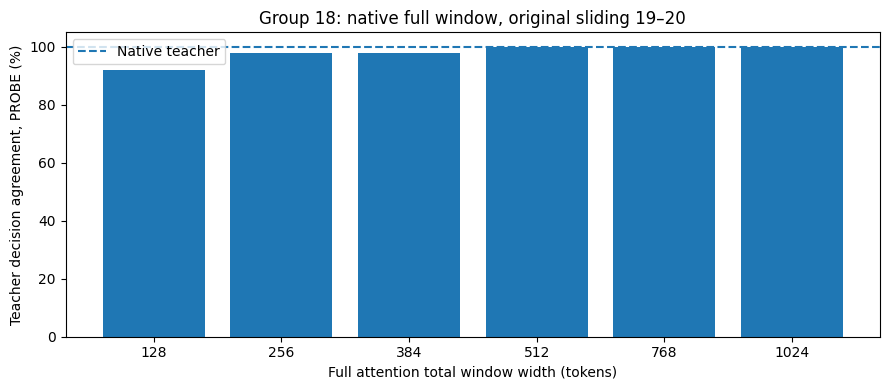

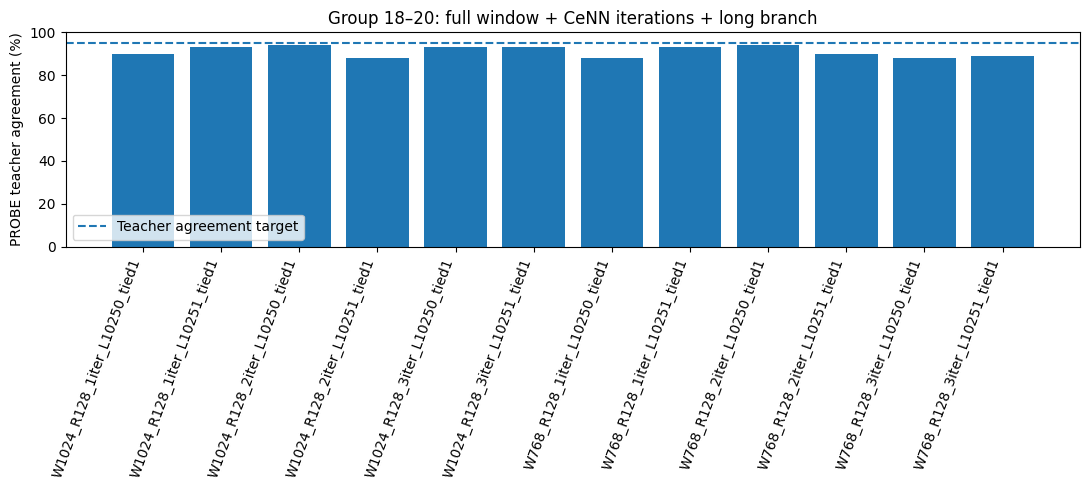

In [11]:
#@title 11. Save complete setting comparison, independently trained adapters and plots
from datetime import datetime,timezone
import matplotlib.pyplot as plt

winner_config=dict(
    width=winner["width"],iterations=winner["iterations"],
    long_branch=winner["long_branch"],tied=winner["tied"],
    rank=CENN_RANK,local_radius=LOCAL_RADIUS,
    long_range_receptive_field=LONG_RF,
)
report=dict(
    version="4.0-group18to20-full-window-CeNN1025-shared128",
    created_utc=datetime.now(timezone.utc).isoformat(),
    pretrained_model=SOURCE_MODEL,
    fixed_group=TARGET,original_full_layers=list(FULL_LAYERS),
    original_sliding_radius=64,
    full_window_candidates=FULL_WINDOWS,
    observed_context=dict(
        minimum=min(observed_lengths),maximum=observed_max,
        median=float(np.median(observed_lengths)),
        task_config_max_len=int(source_cfg.get("max_len",MAX_LEN)),
        requested_max_len=MAX_LEN,
        extended_context_enabled=ALLOW_EXTENDED_CONTEXT,
    ),
    full_window_equivalence={str(w):int(k) for w,k in window_identical.items()},
    full_window_probe_screen=full_window_screen,
    distinct_windows_trained=chosen_windows,
    recurrent_local_radius=LOCAL_RADIUS,
    recurrent_local_total_window=2*LOCAL_RADIUS+1,
    long_range_receptive_field=LONG_RF,
    long_range_weight_separate_from_recurrent_weights=True,
    recurrent_weights_shared_across_iterations=True,
    grid_results={key:dict(
        width=row["width"],iterations=row["iterations"],
        long_branch=row["long_branch"],tied=row["tied"],
        steps=row["trained_steps"],local=row["local"],
        task_probe=row["probe_decisions"],checkpoint=row["checkpoint"]
    ) for key,row in trial_results.items()},
    refined_results={key:dict(
        width=row["width"],iterations=row["iterations"],
        long_branch=row["long_branch"],tied=row["tied"],
        steps=row["trained_steps"],local=row["local"],
        task_probe=row["probe_decisions"],checkpoint=row["checkpoint"]
    ) for key,row in refined_results.items()},
    untied_control=(
        dict(local=untied_control["local"],
             task_probe=untied_control["probe_decisions"],
             config=dict(width=untied_control["width"],
                         iterations=untied_control["iterations"],
                         long_branch=untied_control["long_branch"]),
             checkpoint=untied_control["checkpoint"])
        if untied_control is not None else None
    ),
    selected_configuration=winner_config,
    selected_probe=winner["probe_decisions"],
    heldout_audit=heldout_audit,
    heldout_group_metrics=segment_audit,
    causal_audit_ablations=ablation_audit,
    cuda_paired_whole_model=paired_timings,
    cuda_native_18_20_ms=native_group_ms,
    cuda_compressed_18_20_ms=student_group_ms,
    cuda_18_20_speedup=group_speedup,
    acceptance=gates,
    source_train_cases=TRAIN_CASES,
    source_dev_cases=DEV_CASES,
    independent_audit_decisions=AUDIT_DECISIONS,
    official_test_untouched=True,
    trainable_student_components="Group 18–20 CeNN only; original other 25 layers frozen",
    research_caveats=[
        "All window candidates are actual TOTAL widths; CeNN local value 128 is a radius.",
        "A 1025-token CeNN receptive field is NOT a 1025-iteration recurrent network.",
        "Identical observed band masks imply no independent inference-quality window comparison.",
        "Training is limited to one group, not full 28-layer compression.",
        "The repeated local CeNN spatial kernel is shared, but the long-range kernel is independent.",
        "Original teacher and sliding blocks remain allocated in research runtime.",
        "Only candidate selection uses PROBE. AUDIT is evaluated after selection, once.",
        "Pretrained task decisions may degrade under extended context >512.",
        "A passing small-sample audit is not sufficient for publication/deployment.",
    ],
)
report_file=OUTPUT_DIR/"v40_group18_20_window_cenn1025_128_report.json"
report_file.write_text(json.dumps(report,indent=2,default=str),encoding="utf-8")
checkpoint_file=OUTPUT_DIR/"v40_group18_20_SELECTED_EXPERIMENTAL.pt"
torch.save(dict(
    source_model=SOURCE_MODEL,group=TARGET,
    config=winner_config,
    selected_probe=winner["probe_decisions"],
    audit_gates=gates,deployable=bool(gates["all_pass"]),
    adapter_state=cpu_state(selected_model)
),checkpoint_file)
print("Best setting from PROBE:",winner["id"])
print("Window only screen:",[
    (w,full_window_screen[str(w)]["quality"]["teacher_agreement"])
    for w in FULL_WINDOWS
])
print("Best CeNN setting:",winner_config)
print("Holdout:",heldout_audit)
print("Group local cosine:",segment_audit["cosine"],
      "delta-NMSE:",segment_audit["delta_nmse"])
print("CUDA group speedup:",group_speedup)
print("CUDA whole-model speedups:",
      [round(v["speedup"],3) for v in paired_timings])
print("Model quality + speed PASS:",gates["all_pass"])
print("JSON REPORT:",report_file)
print("CeNN adapter:",checkpoint_file)

labels=[str(w) for w in FULL_WINDOWS]
window_agreements=[
    full_window_screen[str(w)]["quality"]["teacher_agreement"]*100
    for w in FULL_WINDOWS
]
plt.figure(figsize=(9,4))
plt.bar(labels,window_agreements)
plt.axhline(100,linestyle="--",label="Native teacher")
plt.ylabel("Teacher decision agreement, PROBE (%)")
plt.xlabel("Full attention total window width (tokens)")
plt.title("Group 18: native full window, original sliding 19–20")
plt.legend()
plt.tight_layout()
plt.show()

keys=list(trial_results)
agreements=[trial_results[key]["probe_decisions"]["teacher_agreement"]*100
            for key in keys]
plt.figure(figsize=(max(11,len(keys)*.85),5))
plt.bar(keys,agreements)
plt.axhline(95,linestyle="--",label="Teacher agreement target")
plt.xticks(rotation=70,ha="right")
plt.ylim(0,100)
plt.ylabel("PROBE teacher agreement (%)")
plt.title("Group 18–20: full window + CeNN iterations + long branch")
plt.legend()
plt.tight_layout()
plt.show()
